# 문서 파싱과 스크래핑

**이 노트북에서 할 일**

1. 연습용 robots.txt 규칙을 읽고, 두 주소를 이 규칙이 허용하는지 확인합니다.
2. 기사 페이지 HTML 글을 요소 트리로 바꾸고, CSS 선택자로 제목·요약·날짜를 골라 읽습니다.
3. class 이름이 바뀐 페이지에서 멈추는 함수를 고친 뒤, Ch 5가 읽을 JSON 파일을 씁니다.

**준비물** — API 키 불필요. 인터넷에 있는 사이트에는 접속하지 않습니다.
실습 폴더의 `data` 폴더에 든 `robots.txt`와 `article.html`을 읽습니다.
마지막 코드 셀은 같은 폴더에 `article-text.json`을 씁니다. Ch 5 01절이 이 파일을 읽습니다.

모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

**기준 버전** — 실습 폴더에 고정한 beautifulsoup4 4.15.0과 lxml 6.1.3을 씁니다.
선택자를 처리하는 soupsieve 2.9.2도 함께 설치됩니다. 교재 출력은 이 버전들과 Python 3.12.13으로 만들었습니다.

설치 정보에 적힌 Python 요구 버전은 세 패키지가 다릅니다. 패키지 beautifulsoup4는 3.7 이상, lxml은 3.8 이상입니다.
패키지 soupsieve는 3.10 이상을 요구합니다. 다른 버전은 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch04-data-tools`에서 Ch 1 3절처럼 `uv sync --locked`로 환경을 만듭니다.
커널에서 이 폴더의 `.venv`를 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

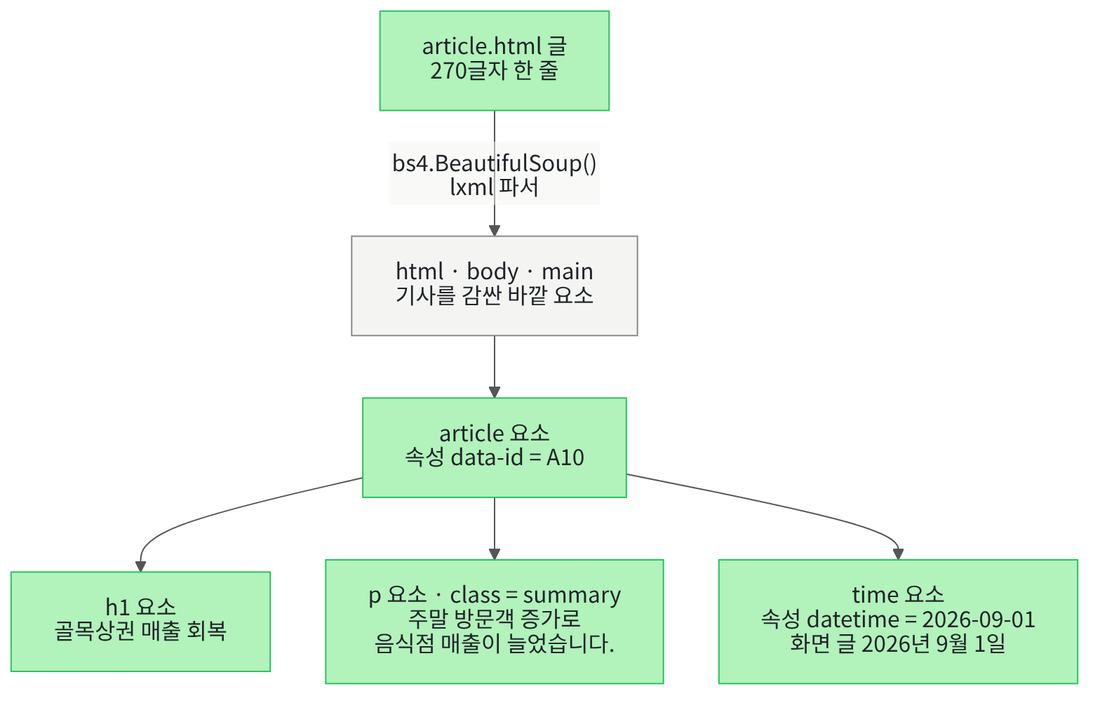

위에서 아래로 읽습니다. 맨 위 초록 상자는 한 줄로 된 HTML 글이고, 화살표의 파서가 이 글을 요소 트리로 바꿉니다.
회색 상자는 기사를 감싼 바깥 요소입니다. 그 아래 기사 요소 article 안에 제목, 요약, 날짜 요소가 나란히 들어 있습니다.

이 노트북은 아래 줄의 세 요소에서 글자와 속성 값을 골라 읽습니다.

## 1. 준비

이 절은 새 연습 파일을 만들지 않습니다. 실습 폴더의 `data` 폴더에 든 파일을 읽고, 마지막에 Ch 5가 읽을 파일 하나를 같은 폴더에 씁니다.
그래서 01~04절처럼 임시 폴더를 만들지 않고, 작업 위치를 `data` 폴더로 옮깁니다.

노트북을 `notebooks` 폴더에서 열면 `data` 폴더는 한 칸 위에 있어 `../data`로 적습니다. Ch 1 02절의 상대 경로입니다.
함수 `os.path.exists()`는 적은 경로에 파일이나 폴더가 있으면 `True`를 반환합니다.
그 경로에 파일이 없으면 프로젝트 맨 위 폴더에서 연 경우로 보고 긴 경로를 씁니다.

In [1]:
# 기사 페이지 파일이 든 실습 폴더의 data 폴더로 작업 위치를 옮깁니다
import os

# notebooks 폴더에서 열면 한 칸 위의 data, 프로젝트 맨 위 폴더에서 열면 긴 경로에 있습니다
data_folder = "../data"
if not os.path.exists("../data/article.html"):
    data_folder = "labs/part1/ch04-data-tools/data"
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(data_folder)
print("article.html이 있는가:", os.path.exists("article.html"))
print("robots.txt가 있는가:", os.path.exists("robots.txt"))

article.html이 있는가: True
robots.txt가 있는가: True


**결과 읽기** — 두 줄 모두 `True`입니다. 작업 위치가 `data` 폴더로 옮겨졌고, 이 절에서 읽을 두 파일이 있습니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 가져오기 전에 — robots.txt 규칙 읽기

웹 페이지에서 필요한 데이터를 프로그램으로 골라 모으는 일을 스크래핑(scraping)이라고 부릅니다.
신문에서 필요한 기사만 오려 두는 일을 프로그램이 하는 셈입니다. 이 절은 저장해 둔 기사 페이지 하나에서 제목과 요약, 날짜를 골라 읽습니다.

페이지를 가져오기 전에 먼저 볼 규칙이 있습니다. 파일 robots.txt는 페이지를 자동으로 가져가는 프로그램에게 들어와도 되는 주소를 알리는 글입니다.
건물 입구의 「관계자 외 출입 금지」 안내판과 비슷합니다. 안내판에 적히지 않은 방이라도 건물 규칙과 저작권은 따로 지켜야 합니다.

실습 폴더의 `robots.txt`는 연습용 주소 `example.test`의 규칙이라고 가정합니다. 끝이 `.test`인 주소는 시험용으로 비워 둔 이름이라 실제 사이트가 없습니다.
표준 라이브러리 모듈 `urllib.robotparser`가 규칙을 읽고 판단합니다. 묶음 `urllib` 안의 모듈이라 점으로 이어 적습니다.

메서드 `can_fetch(프로그램 이름, 주소)`는 규칙이 그 주소를 허용하면 `True`를 반환합니다. 프로그램 이름은 요청하는 프로그램이 스스로 밝히는 이름입니다.
이 메서드는 이미 읽어 들인 규칙만 보고 판단하고, 인터넷에 접속하지 않습니다.

실행 전에 예상합니다. 규칙 줄 `Allow: /articles/`에 맞는 기사 주소는 `True`, `Disallow: /private/`에 맞는 비공개 주소는 `False`일 것입니다.

In [2]:
# robots.txt 규칙을 읽고, 연습용 주소 두 곳을 이 규칙이 허용하는지 묻습니다
import urllib.robotparser

with open("robots.txt", encoding="utf-8") as file:
    rule_lines = file.read().splitlines()
print("규칙 줄:", rule_lines)
# RobotFileParser()는 규칙을 담을 객체를 만들고, parse()가 규칙 줄 목록을 읽어 들입니다
robots = urllib.robotparser.RobotFileParser()
robots.parse(rule_lines)
article_address = "https://example.test/articles/A10"
private_address = "https://example.test/private/A10"
# can_fetch(프로그램 이름, 주소)는 규칙이 허용하면 True를 반환합니다
print("기사 주소를 허용하는가:", robots.can_fetch("course-bot", article_address))
print("비공개 주소를 허용하는가:", robots.can_fetch("course-bot", private_address))

규칙 줄: ['User-agent: *', 'Allow: /articles/', 'Disallow: /private/']
기사 주소를 허용하는가: True
비공개 주소를 허용하는가: False


**결과 읽기** — 규칙 줄은 `['User-agent: *', 'Allow: /articles/', 'Disallow: /private/']`입니다. 첫 줄의 별표는 모든 프로그램에 적용한다는 뜻입니다.
기사 주소는 `True`, 비공개 주소는 `False`로 예상과 같습니다.

이 결과는 robots.txt 규칙만 보고 내린 판단입니다. 사이트의 이용 약관, 저작권, 개인정보, 요청 간격은 이 코드가 확인하지 않습니다.
이 노트북은 페이지를 가져오지 않고, 저장해 둔 페이지 파일을 읽습니다.

## 3. HTML 글 읽기

기사 페이지는 HTML(HyperText Markup Language) 형식의 글입니다. 이 형식은 내용 앞뒤에 꺾쇠 괄호로 된 태그(tag)를 붙여 내용의 역할을 적습니다.
예를 들어 여는 태그 `<time datetime="2026-09-01">`와 닫는 태그 `</time>` 사이의 글은 날짜입니다.

여는 태그부터 닫는 태그까지를 요소(element)라고 부릅니다. 여는 태그 안의 `이름="값"`은 속성(attribute)으로, 요소에 붙이는 추가 정보입니다.
04절의 JSON은 값을 키로 찾았습니다. HTML에서는 요소 이름과 속성으로 값을 찾습니다.

Ch 2 05절처럼 `with open`으로 파일 글을 읽습니다.
실행 전에 예상합니다. 태그와 내용이 줄바꿈 없이 이어진 글이 나올 것입니다.

In [3]:
# 실습 폴더에 저장해 둔 기사 페이지 HTML 파일을 글로 읽습니다
with open("article.html", encoding="utf-8") as file:
    html_text = file.read()
print("HTML 글의 글자 수:", len(html_text))
print("HTML 글:")
print(html_text)

HTML 글의 글자 수: 270
HTML 글:
<!doctype html>
<html lang="ko"><head><meta charset="utf-8"><title>지역 상권 소식</title></head><body><main><article data-id="A10"><h1>골목상권 매출 회복</h1><p class="summary">주말 방문객 증가로 음식점 매출이 늘었습니다.</p><time datetime="2026-09-01">2026년 9월 1일</time></article></main></body></html>



**결과 읽기** — 글자 수는 `270`입니다. 글은 `<!doctype html>`로 시작해 `</html>`로 끝나고, 줄바꿈 없이 한 줄입니다.

가운데의 `<article data-id="A10">`은 기사 요소를 여는 태그이고, `data-id="A10"`이 속성입니다.
그 뒤로 제목 태그 h1, 문단 태그 p, 날짜 태그 `<time datetime="2026-09-01">`의 요소가 이어집니다.
한 줄 글이라 어느 요소가 어느 요소 안에 있는지 눈으로 찾기 어렵습니다.

## 4. 파서로 요소 트리 만들기

HTML 글을 태그와 포함 관계가 있는 구조로 읽는 일을 파싱(parsing)이라고 부릅니다. 그 일을 하는 프로그램은 파서(parser)입니다.
파싱한 결과는 바깥 요소가 안쪽 요소를 품는 나무 모양이라 요소 트리(element tree)라고 부릅니다. 폴더 안에 폴더가 든 모양과 비슷합니다.
어떤 요소 안에 바로 든 요소를 그 요소의 자식 요소라고 부릅니다.

패키지 beautifulsoup4는 HTML을 파싱해 요소 트리를 다루는 기능 묶음이고, import할 때 이름은 `bs4`입니다.
실제로 글을 읽는 파서로는 패키지 lxml을 씁니다. 두 패키지는 실습 폴더의 `uv sync --locked`가 이미 설치했습니다.

함수 `bs4.BeautifulSoup(글, "lxml")`은 lxml 파서로 글을 읽어 요소 트리 객체를 반환합니다.
메서드 `prettify()`는 요소마다 줄을 나누고, 안쪽 요소일수록 더 들여 쓴 글을 반환합니다.

실행 전에 예상합니다. 기사 요소 줄보다 그 안의 제목 요소 줄이 더 들여 쓰여 있을 것입니다.

In [4]:
# bs4로 HTML 글을 요소 트리로 바꾸고, 트리를 들여쓰기한 글로 출력합니다
import bs4
import lxml

print("beautifulsoup4 버전:", bs4.__version__)
print("lxml 버전:", lxml.__version__)
# BeautifulSoup(글, "lxml")은 lxml 파서로 글을 읽어 요소 트리 객체를 반환합니다
soup = bs4.BeautifulSoup(html_text, "lxml")
# prettify()는 요소마다 줄을 나누고 안쪽 요소를 더 들여 쓴 글을 반환합니다
tree_text = soup.prettify()
print("트리 글:")
print(tree_text)

beautifulsoup4 버전: 4.15.0
lxml 버전: 6.1.3
트리 글:
<!DOCTYPE html>
<html lang="ko">
 <head>
  <meta charset="utf-8"/>
  <title>
   지역 상권 소식
  </title>
 </head>
 <body>
  <main>
   <article data-id="A10">
    <h1>
     골목상권 매출 회복
    </h1>
    <p class="summary">
     주말 방문객 증가로 음식점 매출이 늘었습니다.
    </p>
    <time datetime="2026-09-01">
     2026년 9월 1일
    </time>
   </article>
  </main>
 </body>
</html>



**결과 읽기** — 버전 줄은 `beautifulsoup4 버전: 4.15.0`과 `lxml 버전: 6.1.3`입니다. 실습 폴더에 고정한 버전입니다.

트리 글에서 `<article data-id="A10">` 줄 아래의 제목 태그 h1 줄은 한 칸 더 들여 쓰여 있습니다.
요약 문단 태그 p 줄과 날짜 줄 `<time datetime="2026-09-01">`도 h1 줄과 같은 깊이입니다. 세 요소가 모두 기사 요소의 자식 요소라는 뜻입니다.

맨 위 `<html lang="ko">` 안에 `<head>`와 `<body>`가 있고, `<body>` 안의 `<main>`이 기사 요소를 품습니다.
트리 글은 보기 좋게 만든 글이고, 파일 `article.html`은 바뀌지 않았습니다.

## 5. CSS 선택자로 요소 고르기

트리에서 원하는 요소를 고르는 조건 글을 CSS 선택자(CSS selector)라고 부릅니다. 웹 페이지의 모양을 정하는 CSS에서 쓰는 표기입니다.
요소 이름만 적은 선택자 `article`은 이름이 article인 요소를 고릅니다.

메서드 `select_one(선택자)`는 조건에 맞는 첫 요소를 반환하고, 맞는 요소가 없으면 `None`을 반환합니다.
고른 요소의 속성은 딕셔너리처럼 `요소["속성 이름"]`으로 읽습니다.
메서드 `get_text(strip=True)`는 태그를 뺀 안쪽 글자를, 앞뒤 공백을 지워 반환합니다.

실행 전에 예상합니다. 기사 번호 속성은 `A10`, 제목은 `골목상권 매출 회복`일 것입니다.

In [5]:
# 요소 이름 선택자로 기사 요소와 제목 요소를 고르고, 속성과 글자를 읽습니다
# select_one()은 조건에 맞는 첫 요소를, 없으면 None을 반환합니다
article = soup.select_one("article")
print("고른 요소의 이름:", article.name)
print("기사 번호 속성:", article["data-id"])
# 트리 전체가 아니라 기사 요소 안에서 제목 요소를 고릅니다
title_node = article.select_one("h1")
# get_text(strip=True)는 태그를 뺀 글자를 앞뒤 공백 없이 반환합니다
print("제목:", title_node.get_text(strip=True))

고른 요소의 이름: article
기사 번호 속성: A10
제목: 골목상권 매출 회복


**결과 읽기** — 고른 요소의 이름은 `article`, 기사 번호 속성은 `A10`입니다. 속성 값은 화면에 보이지 않지만 여는 태그 안에 있었습니다.

둘째 선택은 트리 전체가 아니라 변수 `article`에서 시작했습니다. 그래서 기사 요소 안의 제목 `골목상권 매출 회복`이 나왔습니다.

## 6. class 선택자와 속성 읽기

요소에 붙인 class 속성은 같은 역할의 요소를 묶는 이름표입니다. 선택자 앞에 점을 찍은 `.summary`는 class 이름이 summary인 요소를 고릅니다.
요약 문단의 여는 태그에 적힌 `class="summary"`가 이 조건에 맞습니다.

날짜 요소 `time`에는 화면에 보이는 글과 속성 `datetime`의 값이 함께 있습니다. 화면 글은 사이트마다 적는 모양이 다를 수 있습니다.
속성 `datetime`의 값은 HTML 규칙이 정한 날짜 모양으로 적습니다.

실행 전에 예상합니다. 화면 글에는 한국어 글자가 섞여 있고, 속성 값은 연-월-일 모양일 것입니다.

In [6]:
# class 선택자로 요약 문단을 고르고, time 요소의 화면 글과 datetime 속성을 나란히 읽습니다
summary_node = article.select_one(".summary")
print("요약:", summary_node.get_text(strip=True))
time_node = article.select_one("time")
print("화면에 보이는 날짜:", time_node.get_text(strip=True))
print("datetime 속성:", time_node["datetime"])

요약: 주말 방문객 증가로 음식점 매출이 늘었습니다.
화면에 보이는 날짜: 2026년 9월 1일
datetime 속성: 2026-09-01


**결과 읽기** — 요약은 `주말 방문객 증가로 음식점 매출이 늘었습니다.`입니다.
화면에 보이는 날짜는 `2026년 9월 1일`이고, datetime 속성은 `2026-09-01`입니다.

같은 날짜라도 화면 글에는 한국어 글자가 섞여 있어, 날짜로 다루려면 글을 다시 풀어야 합니다. 뒤에서 만드는 함수는 날짜를 속성 값에서 읽습니다.

## 7. 값 하나 바꿔 보기 — class 이름이 바뀐 페이지

사이트는 디자인을 고치면서 class 이름을 바꾸기도 합니다. 저장한 글에서 `class="summary"`만 `class="lead"`로 바꾼 페이지를 만듭니다.
글자 바꾸기는 Ch 1 04절의 메서드 `replace()`를 씁니다. 바꾼 페이지를 같은 선택자 `.summary`로 골라 봅니다.

실행 전에 예상합니다. 요약 문단은 그대로 있지만 이름표가 달라져, 선택 결과는 `None`일 것입니다. 오류는 나지 않을 것입니다.

In [7]:
# 요약 문단의 class 이름만 lead로 바꾼 페이지를 만들고, 같은 선택자로 골라 봅니다
changed_html = html_text.replace('class="summary"', 'class="lead"')
changed_soup = bs4.BeautifulSoup(changed_html, "lxml")
changed_summary = changed_soup.select_one(".summary")
print(".summary로 고른 결과:", changed_summary)
# 바뀐 이름표로 고르면 같은 문단이 나오는지 확인합니다
lead_node = changed_soup.select_one(".lead")
print(".lead로 고른 글:", lead_node.get_text(strip=True))

.summary로 고른 결과: None
.lead로 고른 글: 주말 방문객 증가로 음식점 매출이 늘었습니다.


**결과 읽기** — 첫 줄은 `.summary로 고른 결과: None`입니다. 맞는 요소가 없어도 오류는 나지 않았고, `None`이 반환되었습니다.

선택자를 `.lead`로 바꾸면 요약 글 `주말 방문객 증가로 음식점 매출이 늘었습니다.`가 그대로 나옵니다.
내용은 페이지에 있지만, 이름표가 달라져 옛 선택자로는 찾지 못했습니다.

## 8. Before — 고른 결과를 확인하지 않는 함수

이제 5~6절에서 한 일을 함수로 묶습니다. 함수는 HTML 글을 받아 기사 번호, 제목, 요약, 날짜를 담은 딕셔너리를 반환합니다.
01절 `fetch_orders()`와 04절 `fetch_all_orders()`는 딕셔너리 목록을 반환했습니다. 이 페이지에는 기사가 하나라 딕셔너리 하나를 반환합니다.

Before 함수는 고른 결과를 확인하지 않고, 곧바로 `get_text()`를 불러 글자를 읽습니다.
실행 전에 예상합니다. 함수를 정의만 하는 셀이라 출력은 없을 것입니다.

In [8]:
# Before: 고른 요소가 있는지 확인하지 않고 글자를 읽어, 기사 기록 딕셔너리를 반환합니다
def parse_article_before(html_text: str) -> dict:
    soup = bs4.BeautifulSoup(html_text, "lxml")
    article = soup.select_one("article")
    # 고른 결과가 None이어도 확인하지 않고 get_text()를 부릅니다
    title = article.select_one("h1").get_text(strip=True)
    summary = article.select_one(".summary").get_text(strip=True)
    published = article.select_one("time")["datetime"]
    record = {"id": article["data-id"], "title": title,
              "summary": summary, "published": published}
    return record

**결과 읽기** — 출력이 없습니다. 함수 `parse_article_before()`가 정의되었습니다.

원래 페이지와 7절의 바뀐 페이지를 차례로 넣어 부릅니다. 없는 속성이나 메서드를 쓰려 할 때 나는 오류의 이름은 AttributeError입니다.
바뀐 페이지에서 이 오류가 나면 셀이 멈추므로, 03·04절처럼 그 오류 이름만 받는 `try/except`로 감쌉니다.

실행 전에 예상합니다. 원래 페이지는 기록이 나오고, 바뀐 페이지는 속성 오류 메시지가 나올 것입니다.

In [9]:
# Before: 원래 페이지와 class 이름이 바뀐 페이지를 차례로 읽습니다
before_record = parse_article_before(html_text)
print("원래 페이지 기록:", before_record)
try:
    changed_before_record = parse_article_before(changed_html)
    print("바뀐 페이지 기록:", changed_before_record)
except AttributeError as error:
    print("속성 오류:", error)

원래 페이지 기록: {'id': 'A10', 'title': '골목상권 매출 회복', 'summary': '주말 방문객 증가로 음식점 매출이 늘었습니다.', 'published': '2026-09-01'}
속성 오류: 'NoneType' object has no attribute 'get_text'


**결과 읽기** — 원래 페이지 기록은 `'id': 'A10'`부터 `'published': '2026-09-01'`까지 네 칸이 모두 찼습니다.
바뀐 페이지는 기록 줄 없이 `속성 오류: 'NoneType' object has no attribute 'get_text'`가 나왔습니다.

요약을 고른 결과가 `None`이었고, 그 `None`에서 `get_text()`를 부르다 멈췄습니다. 오류 메시지에는 어느 선택자가 비었는지 적혀 있지 않습니다.
실제 프로그램이라면 제대로 읽힌 기사 번호와 날짜도 받지 못한 채 여기서 멈춥니다.

## 9. After — 고른 결과가 None인지 먼저 확인하는 함수

After에서는 글자를 읽는 일을 작은 함수 `find_text()`로 뺍니다. 이 함수는 요소 하나와 선택자를 받습니다.
고른 결과가 `None`이면 찾지 못한 선택자를 출력하고 `None`을 반환합니다. 찾았으면 글자를 반환합니다.

매개변수 `parent`에는 bs4가 만든 요소가 들어옵니다. 이 요소의 자료형 이름은 이 절에서 다루지 않아 타입힌트를 적지 않았습니다.
반환값도 글자이거나 `None`이라 반환 타입힌트를 적지 않았습니다.

실행 전에 예상합니다. 함수를 정의만 하는 셀이라 출력은 없을 것입니다.

In [10]:
# After: 요소 안에서 선택자로 하나를 골라, 있으면 글자를, 없으면 None을 반환합니다
def find_text(parent, selector: str):
    found = parent.select_one(selector)
    if found is None:
        print("찾지 못한 선택자:", selector)
        return None
    return found.get_text(strip=True)

**결과 읽기** — 출력이 없습니다. 함수 `find_text()`가 정의되었습니다.

다음 셀의 After 함수 `parse_article()`은 Before 함수와 거의 같습니다. 제목과 요약을 읽는 두 줄만 `find_text()`로 바꿨습니다.
날짜는 Before처럼 `time` 요소의 속성에서 읽습니다.

실행 전에 예상합니다. 이번에도 정의만 하는 셀이라 출력은 없을 것입니다.

In [11]:
# After: 제목과 요약은 find_text()로 읽어, 요소가 없으면 None이 든 기사 기록을 반환합니다
def parse_article(html_text: str) -> dict:
    soup = bs4.BeautifulSoup(html_text, "lxml")
    article = soup.select_one("article")
    # Before와 달라진 두 줄: 고른 결과가 None인지 find_text()가 먼저 확인합니다
    title = find_text(article, "h1")
    summary = find_text(article, ".summary")
    published = article.select_one("time")["datetime"]
    record = {"id": article["data-id"], "title": title,
              "summary": summary, "published": published}
    return record

**결과 읽기** — 출력이 없습니다. 함수 `parse_article()`이 정의되었습니다.

같은 두 페이지를 넣어 부르고, 기록마다 값이 `None`인 칸 이름을 모읍니다. 딕셔너리의 `items()`와 풀어 담기는 Ch 2 03절에서 배웠습니다.

실행 전에 예상합니다. 바뀐 페이지에서도 셀이 멈추지 않고, 바뀐 페이지의 빈 칸 목록에 `summary`가 들어갈 것입니다.

In [12]:
# After: 두 페이지를 같은 함수로 읽고, 기록마다 값이 None인 칸 이름을 모읍니다
record = parse_article(html_text)
changed_record = parse_article(changed_html)
print("원래 페이지 기록:", record)
print("바뀐 페이지 기록:", changed_record)
page_records = [("원래 페이지", record), ("바뀐 페이지", changed_record)]
for page_name, one_record in page_records:
    empty_keys = []
    for key, value in one_record.items():
        if value is None:
            empty_keys.append(key)
    print(page_name, "빈 칸:", empty_keys)
# 반복이 끝나면 empty_keys에는 마지막 페이지(바뀐 페이지)의 빈 칸이 남습니다
assert empty_keys == ["summary"]

찾지 못한 선택자: .summary
원래 페이지 기록: {'id': 'A10', 'title': '골목상권 매출 회복', 'summary': '주말 방문객 증가로 음식점 매출이 늘었습니다.', 'published': '2026-09-01'}
바뀐 페이지 기록: {'id': 'A10', 'title': '골목상권 매출 회복', 'summary': None, 'published': '2026-09-01'}
원래 페이지 빈 칸: []
바뀐 페이지 빈 칸: ['summary']


**결과 읽기** — 첫 줄은 `찾지 못한 선택자: .summary`로, 바뀐 페이지를 읽을 때 `find_text()`가 출력했습니다.
바뀐 페이지 기록은 `'summary': None`이고, 기사 번호 `'A10'`과 날짜 `'2026-09-01'`은 그대로 들어 있습니다.

마지막 두 줄은 `원래 페이지 빈 칸: []`와 `바뀐 페이지 빈 칸: ['summary']`입니다. 셀은 멈추지 않았고, 비어 있는 칸을 이름으로 알 수 있습니다.
검사 줄 `assert`는 마지막으로 모은 바뀐 페이지의 빈 칸이 `['summary']`인지 확인했고, 멈추지 않았습니다.

빈 칸이 있는 기록은 Ch 5에 넘기지 않습니다. 다음 셀은 빈 칸이 없는 원래 페이지 기록만 파일로 씁니다.

## 10. Ch 5에 넘길 JSON 파일 쓰기

Ch 5 01절은 이 절이 만든 기사 기록을 파일로 읽고, 모델이 글을 나누는 단위인 토큰의 수를 셉니다.
넘길 파일은 `article-text.json`이고, 04절에서 본 JSON 형식으로 씁니다.

기록에는 Ch 5가 읽을 글 칸 `text`를 더합니다. 제목과 요약을 줄바꿈 한 글자 `"\n"`으로 이은 글입니다.
파일 맨 위에는 파일 모양의 이름 `schema_version`과 원본 HTML 경로 `source`를 함께 적습니다. Ch 5 노트북이 이 칸 이름을 그대로 읽으므로 바꾸지 않습니다.

표준 라이브러리 모듈 `json`의 함수 `json.dumps()`는 딕셔너리를 JSON 글로 바꿔 반환합니다.
인자 `ensure_ascii=False`는 한글을 그대로 두고, `indent=2`는 안쪽 칸을 두 칸씩 들여 씁니다.
04절의 메서드 `response.json()`은 JSON 글을 딕셔너리로 바꿨습니다. 이 함수는 반대 방향입니다.

실행 전에 예상합니다. 출력된 JSON 글의 `record` 안에 칸 다섯 개가 있고, `text` 칸 가운데에 `\n`이 보일 것입니다.

In [13]:
# 원래 페이지 기록에 Ch 5가 읽을 text 칸을 더하고, JSON 글로 바꿔 파일에 씁니다
import json

record["text"] = record["title"] + "\n" + record["summary"]
payload = {
    "schema_version": "ch04-parsed-article-v1",
    "source": "labs/part1/ch04-data-tools/data/article.html",
    "record": record,
}
# dumps()는 딕셔너리를 JSON 글로 바꿔 반환합니다
json_text = json.dumps(payload, ensure_ascii=False, indent=2)
with open("article-text.json", "w", encoding="utf-8") as file:
    file.write(json_text + "\n")
print("JSON 글:")
print(json_text)

JSON 글:
{
  "schema_version": "ch04-parsed-article-v1",
  "source": "labs/part1/ch04-data-tools/data/article.html",
  "record": {
    "id": "A10",
    "title": "골목상권 매출 회복",
    "summary": "주말 방문객 증가로 음식점 매출이 늘었습니다.",
    "published": "2026-09-01",
    "text": "골목상권 매출 회복\n주말 방문객 증가로 음식점 매출이 늘었습니다."
  }
}


**결과 읽기** — JSON 글 첫 칸은 `"schema_version": "ch04-parsed-article-v1"`입니다.
칸 `record` 안에는 `"id": "A10"`부터 `"text"`까지 칸 다섯 개가 있습니다.
글 칸 `text`의 값은 `"골목상권 매출 회복\n주말 방문객 증가로 음식점 매출이 늘었습니다."`이고, 가운데 `\n`이 줄바꿈입니다.

셀은 이 글을 `data` 폴더의 `article-text.json`에 썼습니다. 실습 폴더에 처음부터 있던 같은 이름의 파일을 다시 쓴 것입니다.
작업 기록에서 파일 내용의 지문 값(SHA-256)을 비교하니, 실행 전과 바이트까지 같았습니다. 노트북 안에서 다시 읽어 비교하지는 않았습니다.

## 정리

- 파서는 한 줄 HTML 글을 요소 트리로 바꿉니다. 메서드 `select_one()`은 선택자에 맞는 첫 요소를, 없으면 `None`을 반환합니다.
- 고른 결과를 확인하지 않은 함수는 class 이름이 바뀐 페이지에서 AttributeError로 멈췄습니다.
- 결과가 `None`인지 먼저 확인한 함수는 `찾지 못한 선택자: .summary`를 알리고, 빈 칸 `['summary']`를 남겼습니다.
- robots.txt 규칙은 기사 주소를 `True`, 비공개 주소를 `False`로 판단했습니다. 이용 약관, 저작권, 개인정보는 따로 확인합니다.

이번에는 저장해 둔 페이지 하나만 읽었습니다. 실행 환경은 Linux의 Python 3.12.13, beautifulsoup4 4.15.0, lxml 6.1.3입니다.
인터넷의 실제 사이트에서 페이지를 가져오는 일은 실행하지 않았습니다.
다음 06절은 이 챕터의 실습입니다. 01~04절의 도구를 함수로 묶어, 주문 서비스에서 받은 주문으로 고객별 합계를 냅니다.